# Credit Card Default Risk: Visual Analytics

This notebook accompanies the visual analytics study of credit card default risk on the Default of Credit Card Clients dataset. Each figure is followed by analysis in the corresponding report section. The workflow moves from exploratory data analysis, through visually informed feature engineering, to model interpretation, calibration, threshold sensitivity, and behavioural risk stratification.

## Setup and imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA

sns.set(style="whitegrid")

## Data loading

Loads the dataset, drops the identifier column if present, and ensures the target variable is integer encoded. The target is the next-month default indicator.

In [3]:
df = pd.read_csv("dataset.csv")

TARGET = "default.payment.next.month"

# Drop ID if present
if "ID" in df.columns:
    df = df.drop(columns=["ID"])

# Ensure target is integer
df[TARGET] = df[TARGET].astype(int)
df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,20000.0,2,2,1,24,2,2,-1,-1,-2,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,120000.0,2,2,2,26,-1,2,0,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,90000.0,2,2,2,34,0,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,50000.0,2,2,1,37,0,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,50000.0,1,2,1,57,-1,0,-1,0,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0


## Feature engineering

Two behavioural features are derived. Credit utilisation expresses the most recent bill amount as a share of the credit limit. The aggregated repayment-stress feature sums positive repayment-delay values across six months to capture cumulative delinquency rather than isolated late payments. Ordered age bands are also constructed for the demographic visualisation.

In [4]:
# Utilisation: behavioural stress on credit line
df["utilisation"] = df["BILL_AMT1"] / df["LIMIT_BAL"]

# Aggregated repayment-stress feature across months
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
# clip negatives so only delays (0 or more) contribute
df["repay_stress"] = df[pay_cols].clip(lower=0).sum(axis=1)

# age bands for visual analysis
df["age_band"] = pd.cut(
    df["AGE"],
    bins=[20, 30, 40, 50, 60, 80],
    labels=["21-30", "31-40", "41-50", "51-60", "61-79"]
)

## Figure 1: Correlation heatmap

Visualises pairwise correlations among financial and behavioural variables, including the engineered utilisation and repayment-stress features and the default outcome. This identifies which attributes show the strongest associations with default and informs the focus of the subsequent figures.

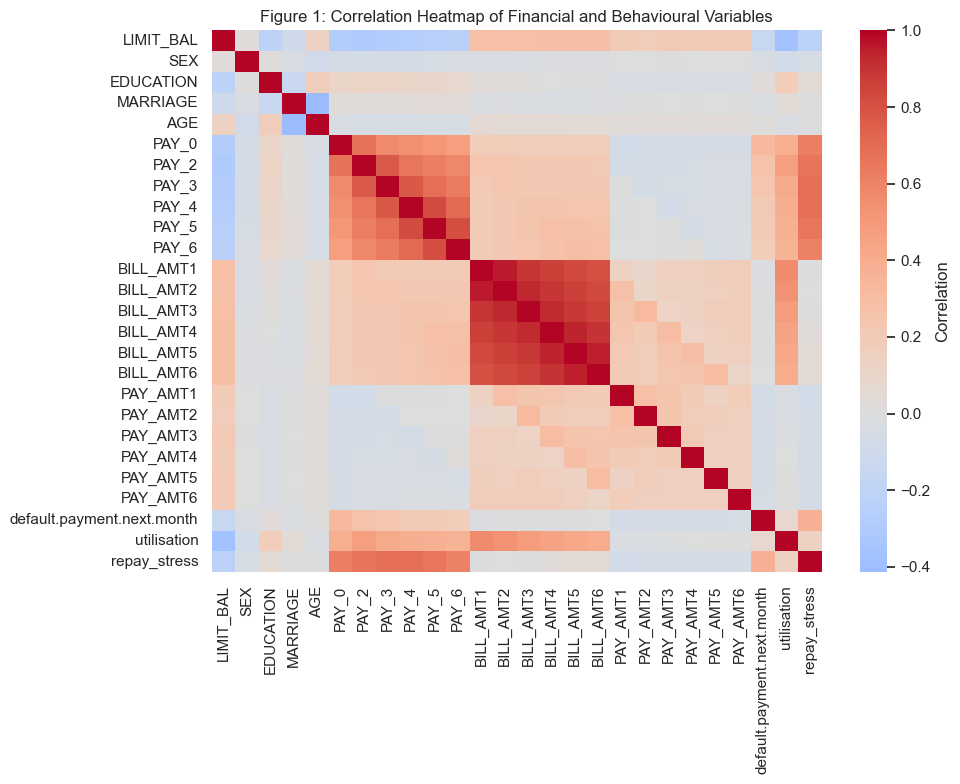

In [5]:
# Figure 1 - Correlation heatmap of numerical vars
plt.figure(figsize=(10, 8))
corr = df.corr(numeric_only=True)

ax = sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Figure 1: Correlation Heatmap of Financial and Behavioural Variables")
plt.xticks(rotation=90)
plt.yticks(rotation=0)

# Get the existing colourbar created by seaborn and label it
cbar = ax.collections[0].colorbar
cbar.set_label("Correlation", rotation=90)

plt.tight_layout()
plt.show()

## Figure 2: Default probability across credit utilisation

Plots the default rate across bins of credit utilisation. The curve highlights non-linear behaviour at higher levels of behavioural stress, motivating the use of utilisation as an engineered feature rather than the raw billing amount.

C:\Users\mario\AppData\Local\Temp\ipykernel_16980\1682280380.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("util_bin")[TARGET]


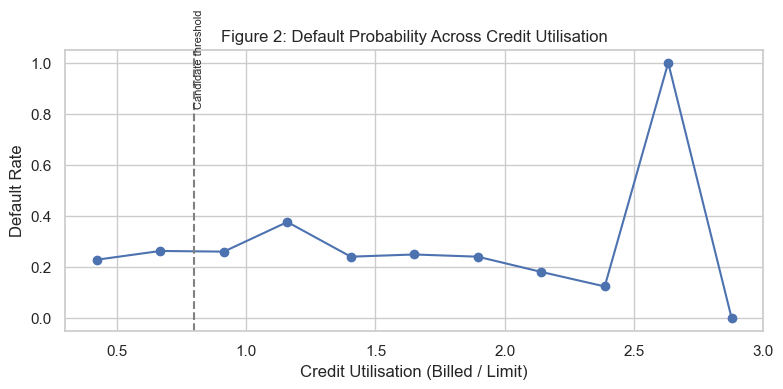

In [6]:
# Figure 2 - Default probability across credit utilisation
# Bin utilisation to smooth the curve
util_bins = np.linspace(0.3, 3.0, 12)
df["util_bin"] = pd.cut(df["utilisation"], bins=util_bins, include_lowest=True)

util_default = (
    df.groupby("util_bin")[TARGET]
    .mean()
    .reset_index()
)
util_default["midpoint"] = util_default["util_bin"].apply(lambda x: x.mid)

plt.figure(figsize=(8, 4))
plt.plot(util_default["midpoint"], util_default[TARGET], marker="o")
threshold = 0.8
plt.axvline(threshold, linestyle="--", color="grey")
plt.text(
    threshold, 0.82,
    "Candidate threshold",
    rotation=90,
    ha="left",
    va="bottom",
    fontsize=8
)
plt.xlabel("Credit Utilisation (Billed / Limit)")
plt.ylabel("Default Rate")
plt.title("Figure 2: Default Probability Across Credit Utilisation")
plt.tight_layout()
plt.show()


## Figure 3: Default rate across recent repayment status

A heatmap of default rate across values of PAY_0, the most recent repayment-delay status. Default probability escalates clearly as repayment delays worsen, indicating temporal persistence in repayment behaviour.

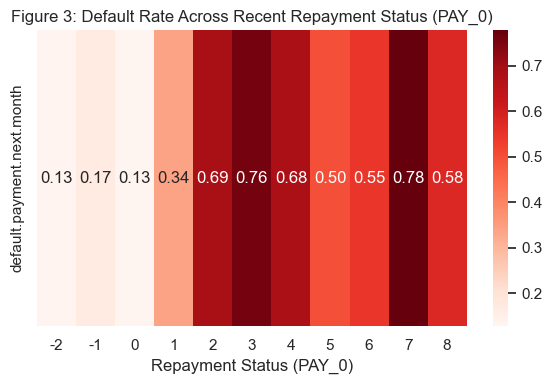

In [7]:
# Figure 3 - Default rate across recent repayment status (PAY_0)
pay_default = df.groupby("PAY_0")[TARGET].mean().reset_index()

# single-row table: row = default rate, columns = PAY_0 categories
pivot_pay = pay_default.set_index("PAY_0").T

plt.figure(figsize=(6, 4))
sns.heatmap(pivot_pay, cmap="Reds", annot=True, fmt=".2f", cbar=True)

plt.xlabel("Repayment Status (PAY_0)")
plt.ylabel("")
plt.title("Figure 3: Default Rate Across Recent Repayment Status (PAY_0)")
plt.tight_layout()
plt.show()

## Figure 4: Default rate by age band and education

A heatmap of default rate across age bands and education levels. The pattern shows interaction effects between demographics and default, supporting the decision to include age and education explicitly in the model.

C:\Users\mario\AppData\Local\Temp\ipykernel_16980\1526853206.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot_age_edu = df.pivot_table(


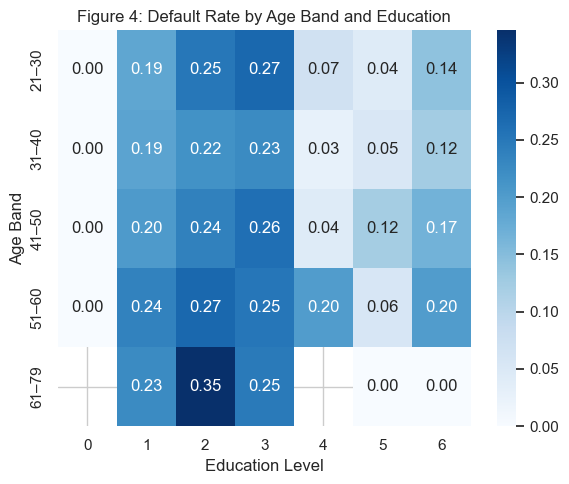

In [8]:
# Figure 4 - Default rate by age band and education
pivot_age_edu = df.pivot_table(
    index="age_band",
    columns="EDUCATION",
    values=TARGET,
    aggfunc="mean"
)

plt.figure(figsize=(6, 5))
sns.heatmap(pivot_age_edu, cmap="Blues", annot=True, fmt=".2f", cbar=True)
plt.xlabel("Education Level")
plt.ylabel("Age Band")
plt.title("Figure 4: Default Rate by Age Band and Education")
plt.tight_layout()
plt.show()

## Figure 5: Effect of transformation on behavioural separation

Three box plots compare default separation across the raw billing amount, the engineered utilisation feature, and the aggregated repayment-stress feature. The transformed features show clearer separation between defaulters and non-defaulters than the raw billing amount.

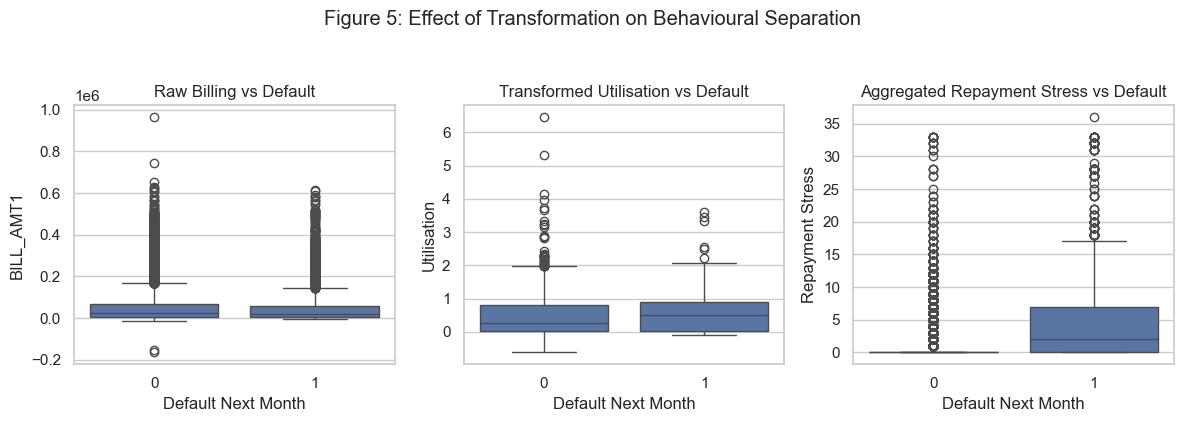

In [9]:
# Figure 5 - Effect of transformation on behavioural separation (3 panels)
plt.figure(figsize=(12, 4))

# 1. Raw billing
plt.subplot(1, 3, 1)
sns.boxplot(x=TARGET, y="BILL_AMT1", data=df)
plt.title("Raw Billing vs Default")
plt.xlabel("Default Next Month")
plt.ylabel("BILL_AMT1")

# 2. Transformed utilisation
plt.subplot(1, 3, 2)
sns.boxplot(x=TARGET, y="utilisation", data=df)
plt.title("Transformed Utilisation vs Default")
plt.xlabel("Default Next Month")
plt.ylabel("Utilisation")

# 3. Aggregated repayment stress
plt.subplot(1, 3, 3)
sns.boxplot(x=TARGET, y="repay_stress", data=df)
plt.title("Aggregated Repayment Stress vs Default")
plt.xlabel("Default Next Month")
plt.ylabel("Repayment Stress")

plt.suptitle("Figure 5: Effect of Transformation on Behavioural Separation", y=1.05)
plt.tight_layout()
plt.show()


## Model training, PCA embedding, and calibration

A logistic regression is fitted using features selected through the visual analysis: credit limit, utilisation, aggregated repayment stress, age, and education. The data are split into 70% training and 30% test, stratified on the target. The fitted model produces predicted default probabilities used in the remaining figures.

In [10]:
# 2. Model training, PCA embedding and calibration
TARGET = "default.payment.next.month"

# Features informed by earlier visual analytics
features = [
    "LIMIT_BAL",
    "utilisation",    # transformed behavioural stress
    "repay_stress",   # aggregated repayment stress
    "AGE",
    "EDUCATION"       # demographic attribute informed by Figure 4
]

X = df[features].copy()
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

model = LogisticRegression(max_iter=3000)
model.fit(X_train, y_train)

y_prob = model.predict_proba(X_test)[:, 1]

test_results = X_test.copy()
test_results["default_actual"] = y_test.values
test_results["default_prob"] = y_prob

## Figure 6: Embedded behavioural risk structure (PCA)

A two-dimensional PCA embedding of the test set, coloured by default outcome. The two classes overlap rather than forming clean clusters, indicating that default risk is continuous and probabilistic rather than deterministic.

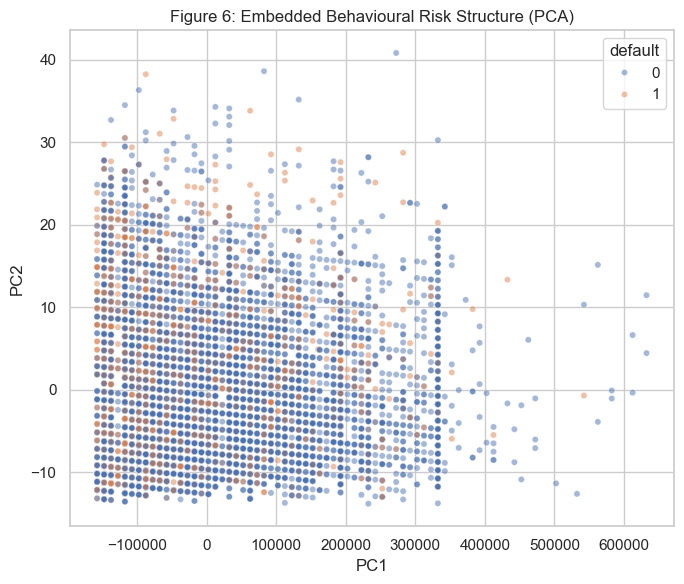

In [11]:
# Figure 6 - Embedded behavioural risk structure (PCA)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_test)

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["default"] = y_test.values

plt.figure(figsize=(7, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="default",
    alpha=0.5,
    s=20
)
plt.title("Figure 6: Embedded Behavioural Risk Structure (PCA)")
plt.tight_layout()
plt.show()


## Figure 7: Calibration of predicted default probabilities

Compares mean predicted probability against observed default rate within ten risk deciles. Deviations from the diagonal reference line indicate segments where the model over or under estimates realised risk.

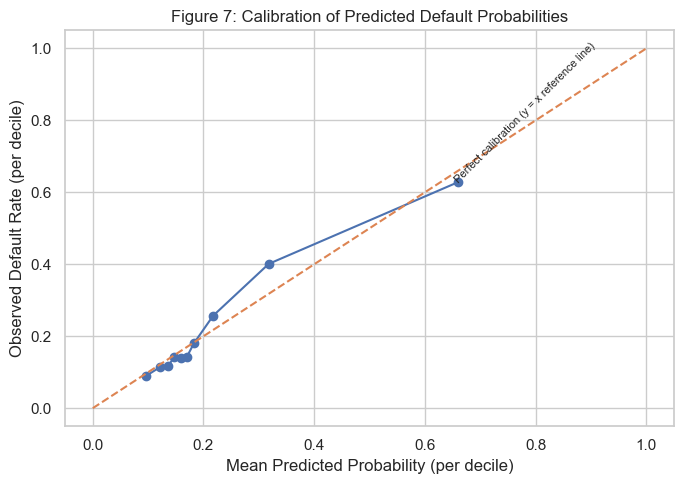

In [12]:
# Figure 7 - Calibration of predicted probabilities
calib_df = pd.DataFrame({"prob": y_prob, "default": y_test.values})
calib_df["decile"] = pd.qcut(calib_df["prob"], 10, labels=False)

decile_stats = (
    calib_df.groupby("decile")
    .agg(mean_prob=("prob", "mean"), mean_default=("default", "mean"))
    .reset_index()
)

plt.figure(figsize=(7, 5))
plt.plot(
    decile_stats["mean_prob"],
    decile_stats["mean_default"],
    marker="o"
)
plt.plot([0, 1], [0, 1], linestyle="--")  # perfect calibration line
plt.text(
    0.65, 0.62,
    "Perfect calibration (y = x reference line)",
    rotation=45,
    ha="left",
    va="bottom",
    fontsize=8
)
plt.xlabel("Mean Predicted Probability (per decile)")
plt.ylabel("Observed Default Rate (per decile)")
plt.title("Figure 7: Calibration of Predicted Default Probabilities")
plt.tight_layout()
plt.show()

## Figure 8: Sensitivity of default classification to threshold

Plots the share of test-set clients flagged as high risk across a range of probability thresholds. The curve shows that classification volume depends strongly on the chosen threshold, framing the threshold as a policy lever shaped by institutional risk appetite.

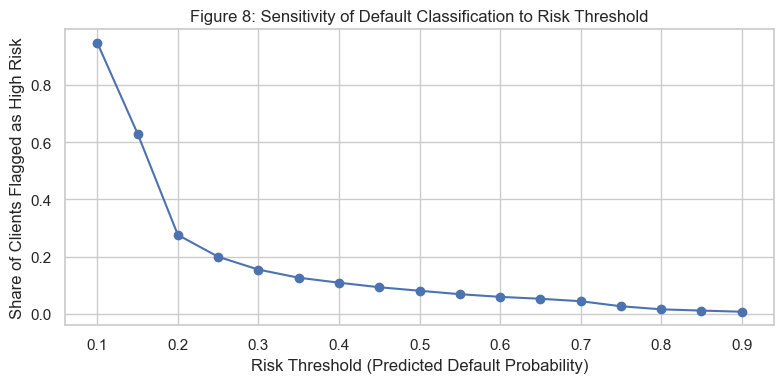

In [57]:
# Figure 8 - Sensitivity of default classification to threshold
thresholds = np.linspace(0.1, 0.9, 17)
flagged_share = []

for t in thresholds:
    flagged = test_results["default_prob"] >= t
    flagged_share.append(flagged.mean())

plt.figure(figsize=(8, 4))
plt.plot(thresholds, flagged_share, marker="o")
plt.xlabel("Risk Threshold (Predicted Default Probability)")
plt.ylabel("Share of Clients Flagged as High Risk")
plt.title("Figure 8: Sensitivity of Default Classification to Risk Threshold")
plt.tight_layout()
plt.show()

## Figure 9: Default rate by behavioural risk band

Groups test-set clients into low, medium, and high behavioural-risk bands using probability cut-points of 0.2 and 0.5. Default rates increase monotonically across the bands, confirming that the segmentation orders clients by risk while preserving overlap consistent with the probabilistic nature of default.

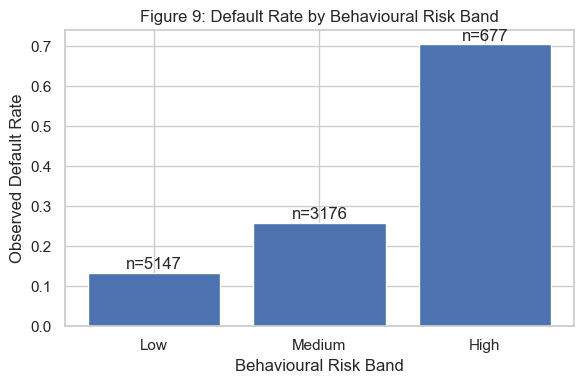

In [25]:
# Figure 9 - Default Rate by Behavioural Risk Band

low_cut = 0.2
high_cut = 0.5

# 1. Define conditions on predicted probability
conditions = [
    test_results["default_prob"] < low_cut,
    (test_results["default_prob"] >= low_cut) & (test_results["default_prob"] < high_cut),
    test_results["default_prob"] >= high_cut,
]

labels = ["Low", "Medium", "High"]

# 2. Create risk_band with a string default
test_results["risk_band"] = np.select(
    conditions,
    labels,
    default="Medium"
)

# 3. Compute default rate and count per band
band_summary = (
    test_results.groupby("risk_band")
    .agg(
        default_rate=("default_actual", "mean"),
        count=("default_actual", "size")
    )
    .reset_index()
)

band_summary["risk_band"] = pd.Categorical(
    band_summary["risk_band"],
    categories=["Low", "Medium", "High"],
    ordered=True,
)
band_summary = band_summary.sort_values("risk_band")

# 4. Plot: Default rate by behavioural risk band
plt.figure(figsize=(6, 4))
plt.bar(band_summary["risk_band"], band_summary["default_rate"])
plt.xlabel("Behavioural Risk Band")
plt.ylabel("Observed Default Rate")
plt.title("Figure 9: Default Rate by Behavioural Risk Band")

for i, row in band_summary.reset_index(drop=True).iterrows():
    plt.text(i, row["default_rate"] + 0.01, f"n={int(row['count'])}", ha="center")

plt.tight_layout()
plt.show()